# Weekly project 6
Today we will continue work from monday.
We will follow the style of last week.

Weekly project:
- You will need to implement your own k-means algorithm. You are not allowed to use the implementation in `sklearn`.
- It should be able to cluster each of the different figures.
- Extend your k-means so it finds the optimal amount of clusters.
  
## Challenge
- Implement the mean shift clustering algorithm


In [2]:
import numpy as np
import open3d as o3d
import copy
import matplotlib.pyplot as plt

def draw_labels_on_model(pcl, labels):
    cmap = plt.get_cmap("tab20")
    pcl_temp = copy.deepcopy(pcl)
    max_label = labels.max()
    colors = cmap(labels / (max_label if max_label > 0 else 1))
    colors[labels < 0] = 0
    pcl_temp.colors = o3d.utility.Vector3dVector(colors[:, :3])
    o3d.visualization.draw_geometries([pcl_temp])

d = 4
mesh = o3d.geometry.TriangleMesh.create_tetrahedron().translate((-d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_octahedron().translate((0, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_icosahedron().translate((d, 0, 0))
mesh += o3d.geometry.TriangleMesh.create_torus().translate((-d, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=1).translate((0, -d, 0))
mesh += o3d.geometry.TriangleMesh.create_mobius(twists=2).translate((d, -d, 0))

## apply k means on this
point_cloud = mesh.sample_points_uniformly(int(1e3))

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [ ]:
def kmeans(point_cloud, k, stop_criteria = 1e-8, max_iter=100):
    """Your implementation goes here

    Args:
    Replace the arguments by what you think is necessary.
        
        k (int): The number of clusters
        stop_criteria (float): The stopping criteria for convergence
        point_cloud (list): The list of points to cluster
    """
    
    # initialize variables
    points = np.asarray(point_cloud.points)    
    idx = np.random.choice(len(points), k, replace=False)
    centroids = points[idx].copy()

    for n in range(max_iter):
        old_centroids = centroids.copy()

        # Calculate distances from points to centroids
        diff = points[:, None, :] - centroids[None, :, :]   # (N, k, d)
        sq_dist = np.sum(diff**2, axis=2)                   # (N, k)

        # assign points to nearest centroid
        labels = np.argmin(sq_dist, axis=1)                 # (N,)

        # update centroids
        for j in range(k):
            members = points[labels == j]
            if len(members) > 0:
                centroids[j] = members.mean(axis=0)
            # else: keep old centroid (or re-seed it at a random point)


        # check for convergence
        total_movement = np.sum(np.linalg.norm(centroids - old_centroids, axis=1))
        if total_movement < stop_criteria:
            break
    sq_dist = np.sum((points[:, None, :] - centroids[None, :, :])**2, axis=2)
    labels = np.argmin(sq_dist, axis=1)    
    distortion = np.sum(sq_dist[np.arange(len(points)), labels])   
     
    return labels, centroids, distortion

labels, centroid, distortion = kmeans(k = 6, stop_criteria=1e-2, point_cloud=point_cloud)

In [10]:
# print(f"Labels: {labels}, Centroids: {centroid}, Distortion: {distortion}")
draw_labels_on_model(point_cloud, labels)

point_cloud has 6 clusters


libdecor-gtk-WARNING: Failed to initialize GTK
Failed to load plugin 'libdecor-gtk.so': failed to init
No plugins found, falling back on no decorations


In [23]:
def find_kmeans_distortions(point_cloud, max_k=10, stop_criteria=1e-8, max_iter=100):
    distortions = []
    for k in range(1, max_k + 1):
        labels, centroids, distortion = kmeans(point_cloud, k, stop_criteria, max_iter)
        distortions.append(distortion)
    return distortions

def calc_distortion_slopes(distortions):
    slopes = []
    for i in range(1, len(distortions)):
        slope = distortions[i] - distortions[i - 1]
        slopes.append(slope)
    return slopes

def calc_distortion_acceleration(slopes):
    acceleration = []
    for i in range(1, len(slopes)):
        acc = slopes[i] - slopes[i - 1]
        acceleration.append(acc)
    return acceleration

def find_elbow_point(acceleration):
    elbow_point = np.argmax(acceleration) + 2
    return elbow_point

In [24]:
def plot_distortions(distortions):
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(distortions) + 1), distortions, marker='o')
    plt.title('Distortion vs. Number of Clusters (k)')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Distortion')
    plt.xticks(range(1, len(distortions) + 1))
    plt.grid()
    plt.show()

In [25]:
distortions = find_kmeans_distortions(point_cloud, max_k=10, stop_criteria=1e-2, max_iter=100)
slopes = calc_distortion_slopes(distortions)
acceleration = calc_distortion_acceleration(slopes)
elbow_point = find_elbow_point(acceleration)

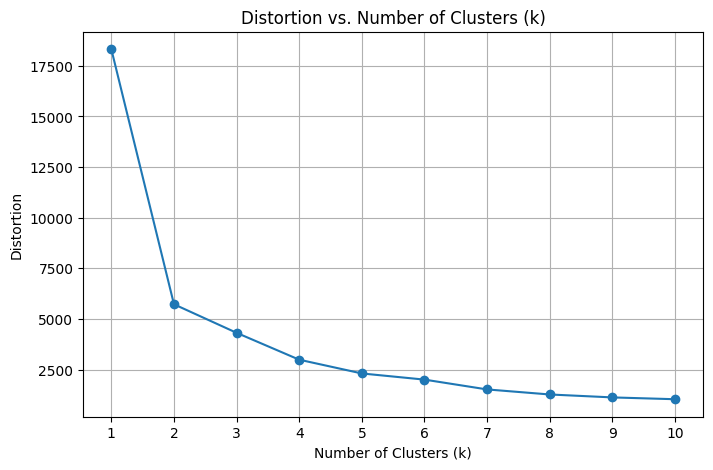

In [28]:
plot_distortions(distortions)

In [27]:
print(f"Elbow point (optimal k): {elbow_point}")

Elbow point (optimal k): 2
